<a href="https://colab.research.google.com/github/ramithuh/differentiable-trees/blob/main/Sankoff_Algorithm_in_JAX.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import jax
import numpy as np
import jax.nn as nn
import jax.numpy as jnp
import matplotlib.pyplot as plt


### Define adjacency matrix

In [2]:
adj = jnp.array([[0,0,0,0,0,1,0,0,0],
                 [0,0,0,0,0,1,0,0,0],
                 [0,0,0,0,0,0,0,1,0],
                 [0,0,0,0,0,0,1,0,0],
                 [0,0,0,0,0,0,1,0,0],
                 [0,0,0,0,0,0,0,0,1],
                 [0,0,0,0,0,0,0,1,0],
                 [0,0,0,0,0,0,0,0,1],
                 [0,0,0,0,0,0,0,0,0]])

### Define cost matrix and leaf sequences

In [3]:
cost_mat = jnp.array([[0.  ,2.5 ,1   ,2.5],
                      [2.5 ,0.  ,2.5 ,1. ],
                      [1.  ,2.5 ,0   ,2.5],
                      [2.5 ,1.  ,2.5 ,0  ]])

seq = jnp.array([[1, 0, 1, 0, 2],
                 [2, 3, 2, 3, 0]])

In [4]:
n_nodes = adj.shape[0]
n_letters = 4
n_leaves = 5

### Base DP Function

In [5]:
def run_dp(dp, dp_nodes, seq, verbose = False):
  for i in range(0,n_leaves):
    dp =  dp.at[i,seq[i]].set(0)


  for node in range(n_leaves, n_nodes):
    ind = jnp.argpartition(adj[:,node], -1)[-2:]

    left_node  = ind[0]
    right_node = ind[1]

    if(verbose):
      print(f"at node {node+1} children are : {left_node+1} and {right_node+1}")

    for i in range(n_letters):
    

      left_cost_array = cost_mat[i][::] + dp[left_node][::]
      left_cost = jnp.min(left_cost_array)
      left_char = jnp.argmin(left_cost_array)


      right_cost_array = cost_mat[i][::] + dp[right_node][::]
      right_cost = jnp.min(right_cost_array)
      right_char = jnp.argmin(right_cost_array)

      dp       = dp.at[node,i].set(left_cost + right_cost)

      dp_nodes = dp_nodes.at[node, i, 0].set(left_node)
      dp_nodes = dp_nodes.at[node, i, 1].set(left_char)

      dp_nodes = dp_nodes.at[node, i, 2].set(right_node)
      dp_nodes = dp_nodes.at[node, i, 3].set(right_char)

      # dp_nodes[...,node][i] = {str(left_node) : left_char, str(right_node) : right_char}

  return dp, dp_nodes

In [6]:
## Vectorize the function

seq_dp = jax.vmap(run_dp, (0, 0, 0, None), 0)

### Regular DP

In [7]:
dp_nodes = jnp.zeros((seq.shape[0], n_nodes, n_letters, 4))

dp = jnp.ones((n_nodes, n_letters))*1e3
dp, connections = run_dp(dp, dp_nodes[0], seq[0], False)

In [8]:
dp

Array([[1000. ,    0. , 1000. , 1000. ],
       [   0. , 1000. , 1000. , 1000. ],
       [1000. ,    0. , 1000. , 1000. ],
       [   0. , 1000. , 1000. , 1000. ],
       [1000. , 1000. ,    0. , 1000. ],
       [   2.5,    2.5,    3.5,    3.5],
       [   1. ,    5. ,    1. ,    5. ],
       [   3.5,    3.5,    3.5,    4.5],
       [   6. ,    6. ,    7. ,    8. ]], dtype=float64)

In [9]:
connections

Array([[[0., 0., 0., 0.],
        [0., 0., 0., 0.],
        [0., 0., 0., 0.],
        [0., 0., 0., 0.]],

       [[0., 0., 0., 0.],
        [0., 0., 0., 0.],
        [0., 0., 0., 0.],
        [0., 0., 0., 0.]],

       [[0., 0., 0., 0.],
        [0., 0., 0., 0.],
        [0., 0., 0., 0.],
        [0., 0., 0., 0.]],

       [[0., 0., 0., 0.],
        [0., 0., 0., 0.],
        [0., 0., 0., 0.],
        [0., 0., 0., 0.]],

       [[0., 0., 0., 0.],
        [0., 0., 0., 0.],
        [0., 0., 0., 0.],
        [0., 0., 0., 0.]],

       [[0., 1., 1., 0.],
        [0., 1., 1., 0.],
        [0., 1., 1., 0.],
        [0., 1., 1., 0.]],

       [[3., 0., 4., 2.],
        [3., 0., 4., 2.],
        [3., 0., 4., 2.],
        [3., 0., 4., 2.]],

       [[2., 1., 6., 0.],
        [2., 1., 6., 0.],
        [2., 1., 6., 2.],
        [2., 1., 6., 0.]],

       [[5., 0., 7., 0.],
        [5., 1., 7., 1.],
        [5., 0., 7., 2.],
        [5., 1., 7., 1.]]], dtype=float64)

### Vectorized DP along character dimension of sequence

In [10]:
dp_nodes = jnp.zeros((seq.shape[0], n_nodes, n_letters, 4))

dp = jnp.ones((2,n_nodes, n_letters))*1e3
dp, connections = seq_dp(dp, dp_nodes, seq, False)

In [11]:
dp

Array([[[1000. ,    0. , 1000. , 1000. ],
        [   0. , 1000. , 1000. , 1000. ],
        [1000. ,    0. , 1000. , 1000. ],
        [   0. , 1000. , 1000. , 1000. ],
        [1000. , 1000. ,    0. , 1000. ],
        [   2.5,    2.5,    3.5,    3.5],
        [   1. ,    5. ,    1. ,    5. ],
        [   3.5,    3.5,    3.5,    4.5],
        [   6. ,    6. ,    7. ,    8. ]],

       [[1000. , 1000. ,    0. , 1000. ],
        [1000. , 1000. , 1000. ,    0. ],
        [1000. , 1000. ,    0. , 1000. ],
        [1000. , 1000. , 1000. ,    0. ],
        [   0. , 1000. , 1000. , 1000. ],
        [   3.5,    3.5,    2.5,    2.5],
        [   2.5,    3.5,    3.5,    2.5],
        [   3.5,    6. ,    3.5,    5. ],
        [   7. ,    9.5,    6. ,    7.5]]], dtype=float64)

In [12]:
connections.shape

(2, 9, 4, 4)

In [13]:
dp

Array([[[1000. ,    0. , 1000. , 1000. ],
        [   0. , 1000. , 1000. , 1000. ],
        [1000. ,    0. , 1000. , 1000. ],
        [   0. , 1000. , 1000. , 1000. ],
        [1000. , 1000. ,    0. , 1000. ],
        [   2.5,    2.5,    3.5,    3.5],
        [   1. ,    5. ,    1. ,    5. ],
        [   3.5,    3.5,    3.5,    4.5],
        [   6. ,    6. ,    7. ,    8. ]],

       [[1000. , 1000. ,    0. , 1000. ],
        [1000. , 1000. , 1000. ,    0. ],
        [1000. , 1000. ,    0. , 1000. ],
        [1000. , 1000. , 1000. ,    0. ],
        [   0. , 1000. , 1000. , 1000. ],
        [   3.5,    3.5,    2.5,    2.5],
        [   2.5,    3.5,    3.5,    2.5],
        [   3.5,    6. ,    3.5,    5. ],
        [   7. ,    9.5,    6. ,    7.5]]], dtype=float64)

### Backtrack and find the actual characters

In [14]:
def backtrack_and_find_nodes(node, letter, seq_chars, connections):

  if(node <= n_letters):
    return seq_chars


  seq_chars = seq_chars.at[node].set(letter)

  child = connections[node,letter]

  seq_chars = backtrack_and_find_nodes(child[0].astype(int), child[1].astype(int), seq_chars, connections)
  seq_chars = backtrack_and_find_nodes(child[2].astype(int), child[3].astype(int), seq_chars, connections)

  return seq_chars

In [15]:
# def backtrack_and_find_nodes(node, letter, seq_chars, connections):
#     stack = [(node, letter)]

#     while stack:
#         current_node, current_letter = stack.pop()

#         if current_node > n_letters:
#           seq_chars = seq_chars.at[..., current_node].set(current_letter)
#           child1 = connections[..., current_node, current_letter][:2].astype(int)
#           child2 = connections[..., current_node, current_letter][2:].astype(int)

#           stack.append((child1[0], child1[1]))
#           stack.append((child2[0], child2[1]))


#     return seq_chars

In [16]:
# backtrack = jax.vmap(backtrack_and_find_nodes, (None, None, 0, 0), 0)

In [17]:
seq_chars = jnp.zeros((seq.shape[0], n_nodes,1)) 
node = adj.shape[0] - 1

sequences = jnp.zeros((n_nodes, seq.shape[0]))
sequences = sequences.at[:n_leaves,::].set(seq.T)


for i in range(0,seq.shape[0]):
  letter = jnp.argmin(dp[i,node,:])
  print(letter)

  chars = backtrack_and_find_nodes(node, letter, seq_chars[i], connections[i]).reshape(n_nodes,)

  sequences = sequences.at[n_leaves:,i].set(chars[n_leaves:])

0
2


In [18]:
sequences

Array([[1., 2.],
       [0., 3.],
       [1., 2.],
       [0., 3.],
       [2., 0.],
       [0., 2.],
       [0., 0.],
       [0., 2.],
       [0., 2.]], dtype=float64)

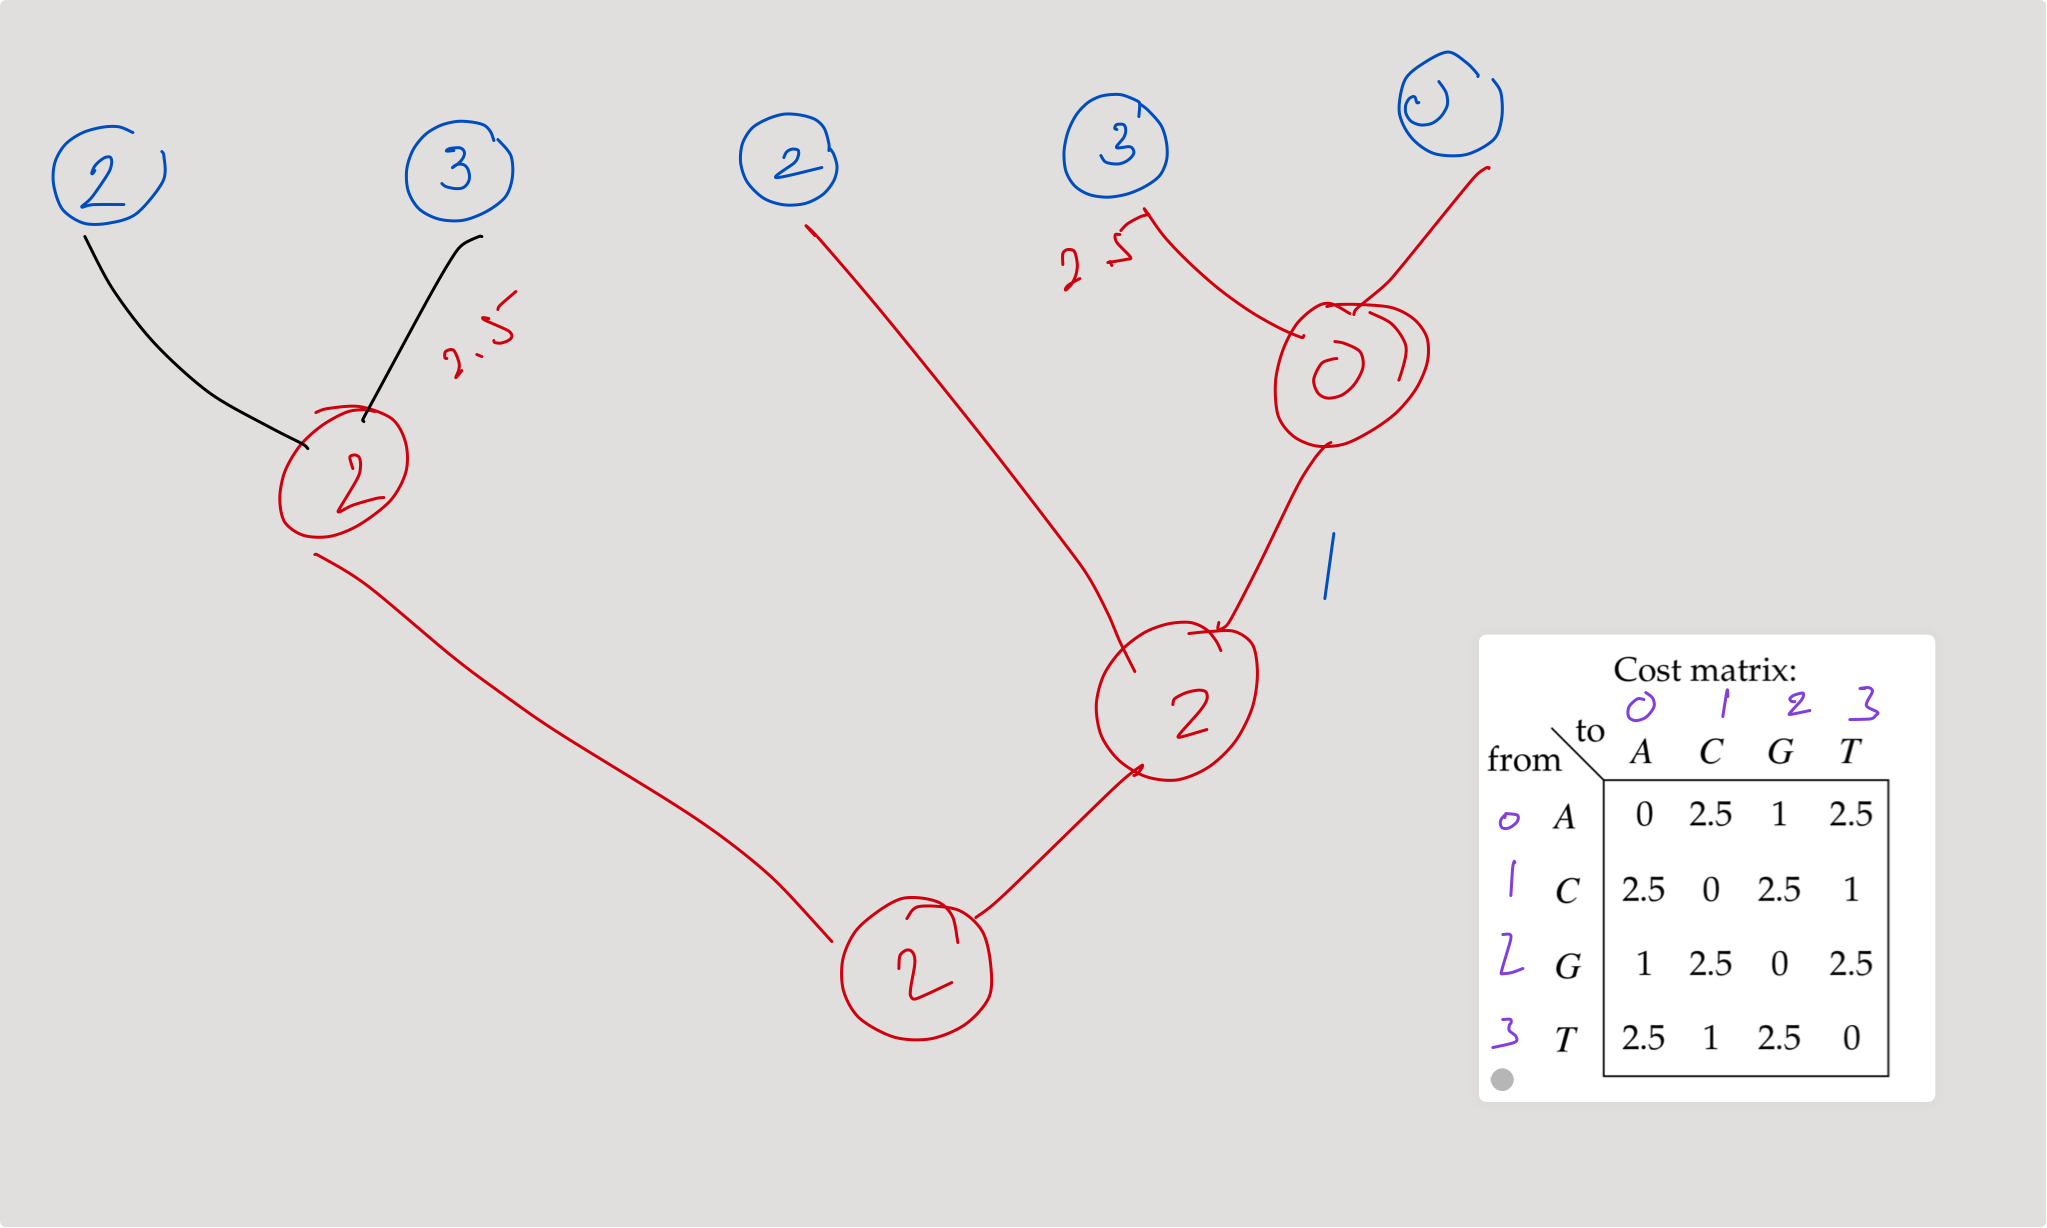

In [19]:
dp

Array([[[1000. ,    0. , 1000. , 1000. ],
        [   0. , 1000. , 1000. , 1000. ],
        [1000. ,    0. , 1000. , 1000. ],
        [   0. , 1000. , 1000. , 1000. ],
        [1000. , 1000. ,    0. , 1000. ],
        [   2.5,    2.5,    3.5,    3.5],
        [   1. ,    5. ,    1. ,    5. ],
        [   3.5,    3.5,    3.5,    4.5],
        [   6. ,    6. ,    7. ,    8. ]],

       [[1000. , 1000. ,    0. , 1000. ],
        [1000. , 1000. , 1000. ,    0. ],
        [1000. , 1000. ,    0. , 1000. ],
        [1000. , 1000. , 1000. ,    0. ],
        [   0. , 1000. , 1000. , 1000. ],
        [   3.5,    3.5,    2.5,    2.5],
        [   2.5,    3.5,    3.5,    2.5],
        [   3.5,    6. ,    3.5,    5. ],
        [   7. ,    9.5,    6. ,    7.5]]], dtype=float64)

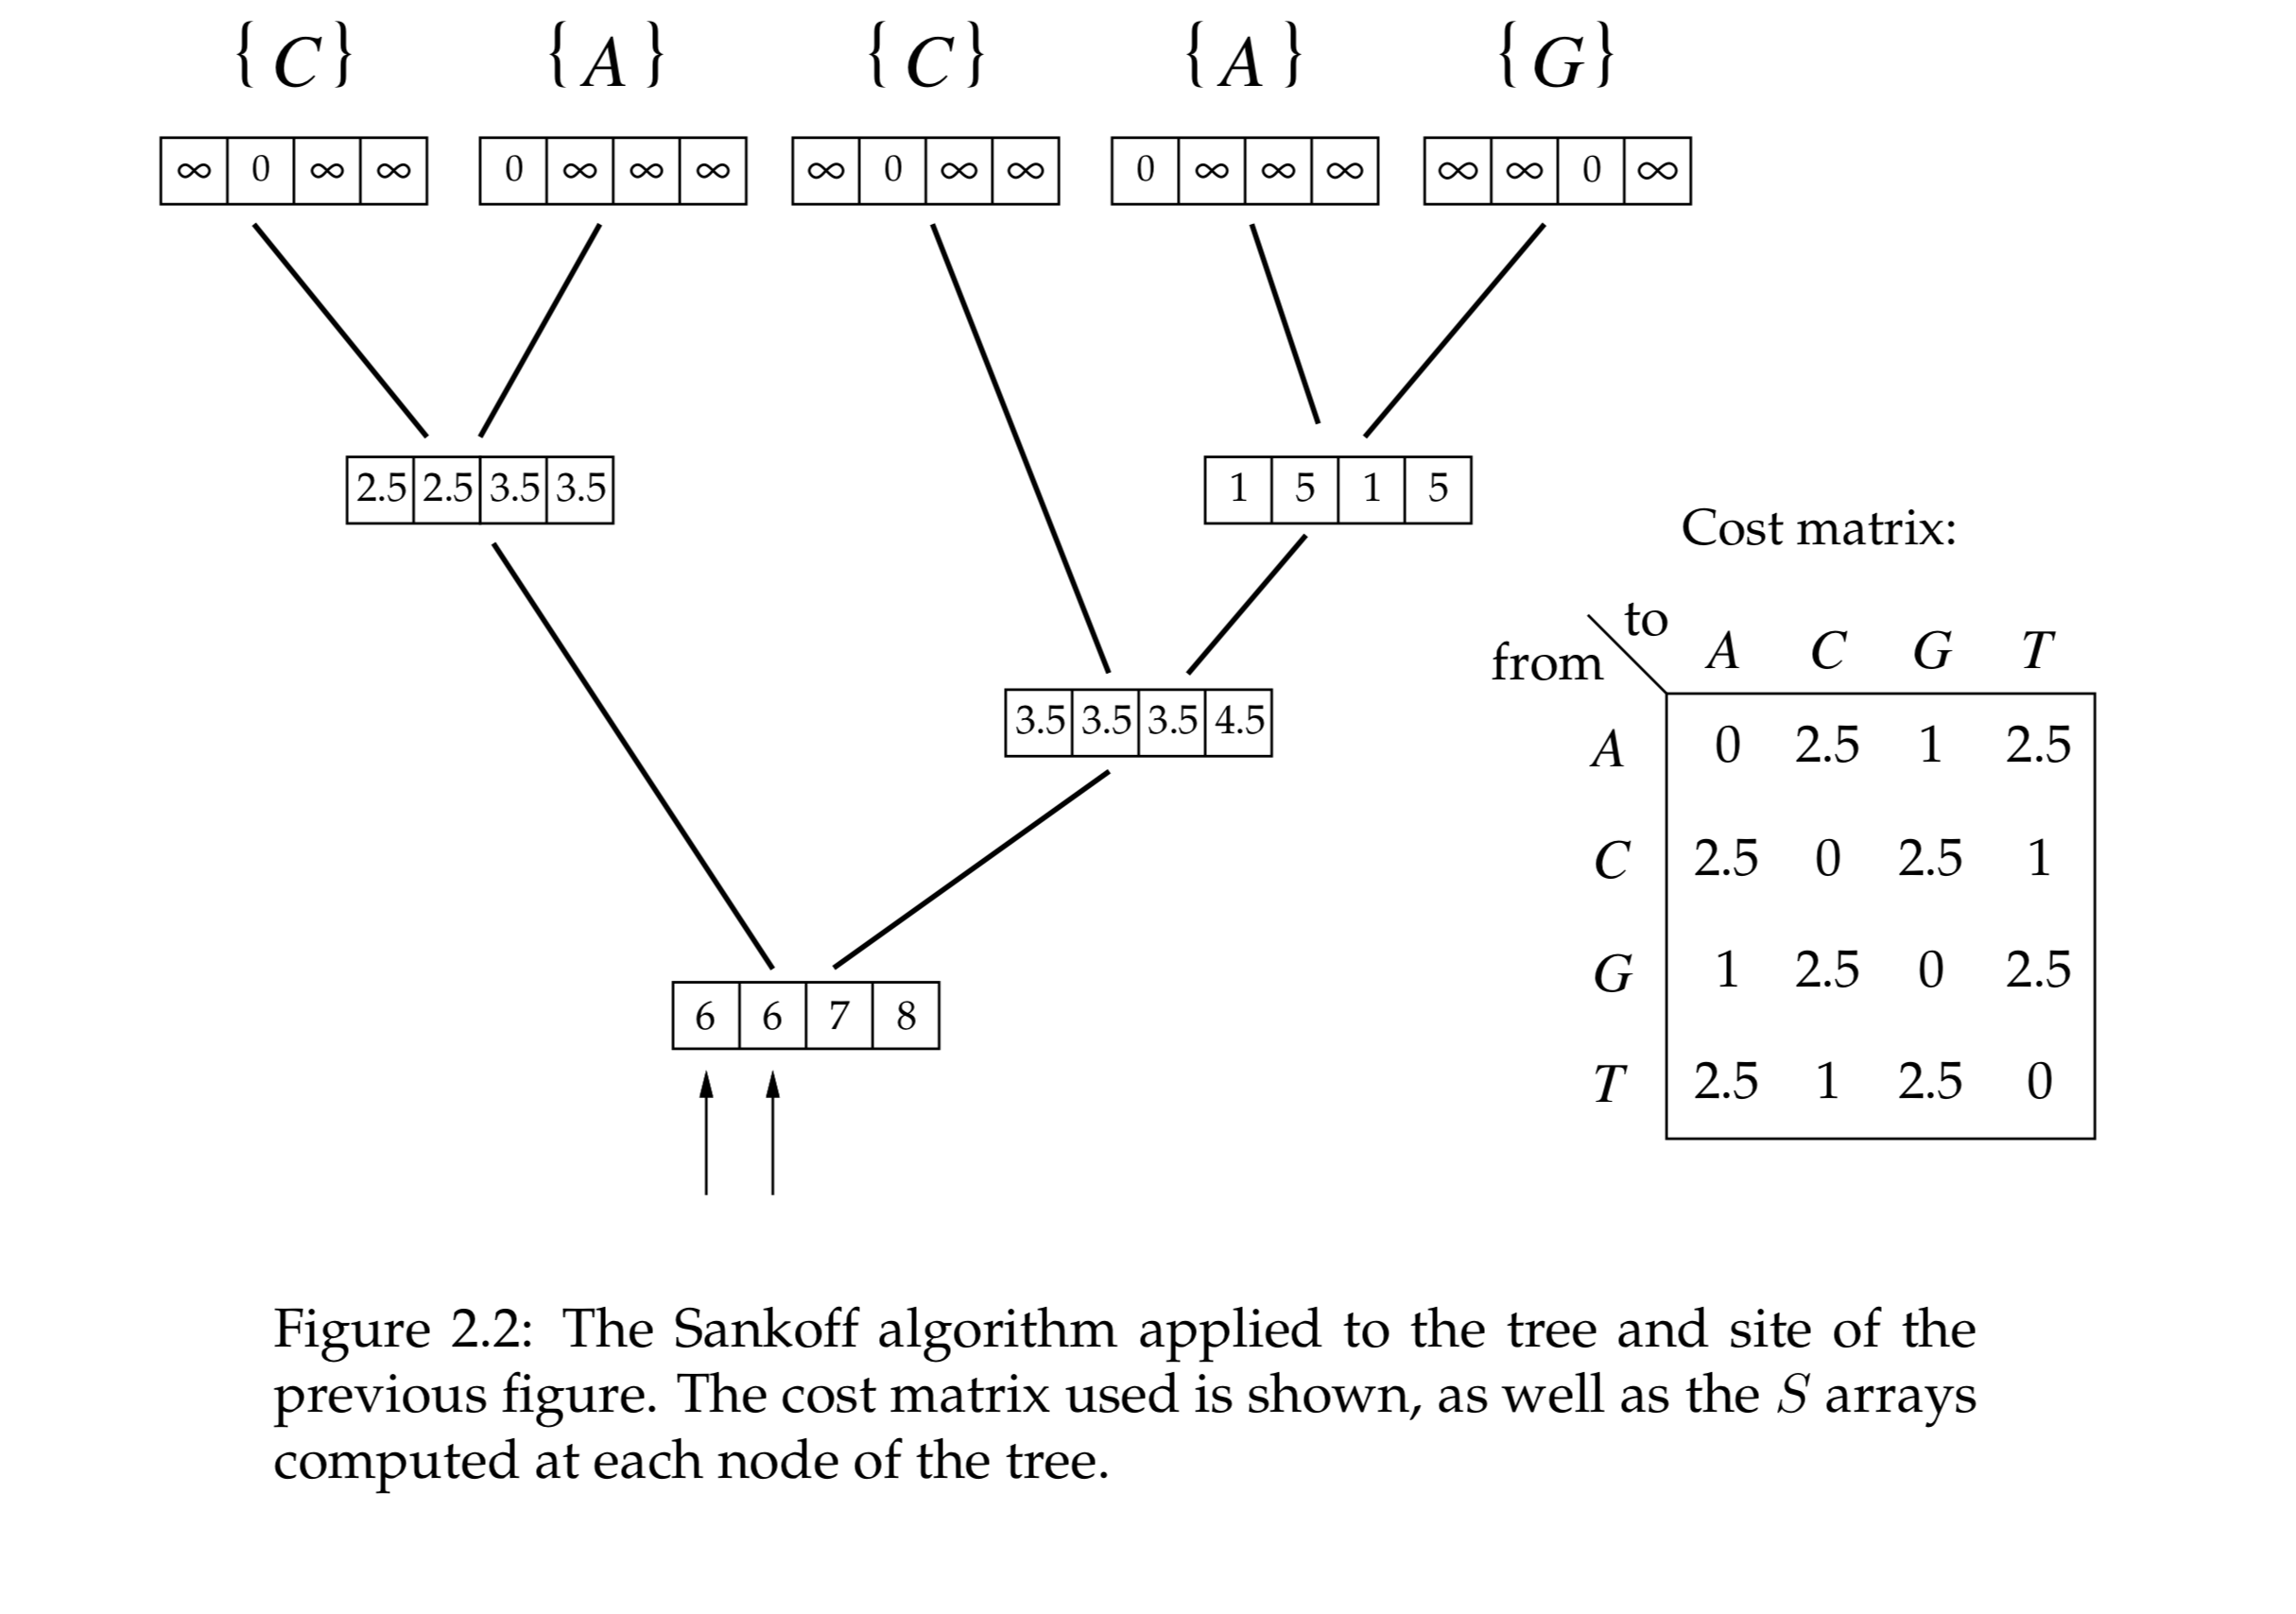